# 实验5C：GPT-1 条件生成情感标签

In [1]:
EXPERIMENT='exp5C'
TITLE='GPT-1'
from pathlib import Path
import os, sys, random, json, time, copy, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
ROOT=Path.cwd() if (Path.cwd()/'exp5').is_dir() else Path.cwd().parent
BASE=ROOT/'exp5'; DATA=BASE/'data'; CACHE=BASE/'.cache'; RESULT=BASE/'results'/EXPERIMENT
for p in [DATA,CACHE,RESULT]: p.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(ROOT/'exp4/.cache/python'))
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'font.sans-serif':['Microsoft YaHei','SimHei','DejaVu Sans'],'axes.unicode_minus':False,'figure.dpi':110})
SENTENCE='今天终于通过了考试，我真的很开心！'
print(sys.executable,torch.__version__,device)
def savefig(name):
    plt.savefig(RESULT/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def metrics(y,p):
    pr,re,f,_=precision_recall_fscore_support(y,p,labels=[0,1,2],average='macro',zero_division=0)
    return dict(Accuracy=accuracy_score(y,p),Precision_macro=pr,Recall_macro=re,F1_macro=f)
def code_image(code):
    import textwrap
    code='\n'.join(part for line in code.splitlines() for part in (textwrap.wrap(line,width=110,subsequent_indent='    ',replace_whitespace=False) or ['']))
    fig,ax=plt.subplots(figsize=(13,max(3,len(code.splitlines())*.24))); ax.axis('off')
    ax.text(0,1,code,va='top',fontfamily=['Consolas','Microsoft YaHei'],fontsize=9,transform=ax.transAxes); savefig('model_code')


E:\CODE\DeepLearning-exp\.cache\exp5-env\Scripts\python.exe 2.14.1+cu130 cuda


In [2]:
# 缺少本地模型文件时，从指定官方模型仓库下载；以后复用缓存。
import requests
model_files={'google-bert/bert-base-chinese':['config.json','model.safetensors','vocab.txt','tokenizer_config.json','tokenizer.json'],
             'openai-community/openai-gpt':['config.json','model.safetensors','vocab.json','merges.txt','tokenizer_config.json','tokenizer.json']}
needed=list(model_files) if EXPERIMENT=='exp5A' else [list(model_files)[0 if EXPERIMENT=='exp5B' else 1]]
for repo in needed:
    directory=CACHE/repo.split('/')[-1];directory.mkdir(exist_ok=True)
    for filename in model_files[repo]:
        target=directory/filename
        if target.exists():continue
        response=requests.get(f'https://huggingface.co/{repo}/resolve/main/{filename}',stream=True,timeout=180);response.raise_for_status()
        temp=target.with_suffix(target.suffix+'.tmp')
        with temp.open('wb') as f:
            for chunk in response.iter_content(1024*1024):f.write(chunk)
        temp.replace(target)
print('模型文件就绪')


模型文件就绪


## 数据与解释边界
数据来自指定的 [Chinese Multi-Emotion Dialogue Dataset](https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset)。繁简转换、去重、排除冲突后分层划分70%/15%/15%；惊奇、关切等映射中性是实验约定，存在语境歧义。测试集只用于最终评价。注意力是权重分布，不能单独当成模型决策的因果解释。

In [3]:
import requests, re
from opencc import OpenCC
from sklearn.model_selection import train_test_split
raw=DATA/'emotion_raw.csv'
if not raw.exists():
    old=ROOT/'exp4/data/emotion_raw.csv'
    if old.exists(): raw.write_bytes(old.read_bytes())
    else:
        r=requests.get('https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset/resolve/main/data.csv',timeout=60);r.raise_for_status();raw.write_bytes(r.content)
cc=OpenCC('t2s'); df=pd.read_csv(raw).dropna(subset=['text','emotion'])
mapping={'开心语调':0,'悲伤语调':1,'愤怒语调':1,'厌恶语调':1,'平淡语气':2,'惊奇语调':2,'关切语调':2,'疑问语调':2}
names=['正面','负面','中性']
df['text_clean']=df.text.map(lambda s:re.sub(r'\s+','',cc.convert(s)))
df['label']=df.emotion.map(cc.convert).map(mapping)
assert df.label.notna().all(),df[df.label.isna()].emotion.unique()
conflict=df.groupby('text_clean').label.nunique(); df=df[~df.text_clean.isin(conflict[conflict>1].index)]
df=df[df.text_clean.str.len()>0].drop_duplicates('text_clean').reset_index(drop=True);df.label=df.label.astype(int)
tr,rest=train_test_split(np.arange(len(df)),test_size=.3,stratify=df.label,random_state=SEED)
va,te=train_test_split(rest,test_size=.5,stratify=df.loc[rest,'label'],random_state=SEED)
df['split']='train';df.loc[va,'split']='val';df.loc[te,'split']='test'
df.to_csv(RESULT/'data_split.csv',index=False,encoding='utf-8-sig')
pd.DataFrame([{'original':k,'target':names[v]} for k,v in mapping.items()]).to_csv(RESULT/'label_mapping.csv',index=False,encoding='utf-8-sig')
display(pd.crosstab(df.split,df.label).rename(columns=dict(enumerate(names))))


label,正面,负面,中性
split,,,
test,89,213,322
train,413,992,1502
val,89,212,322


## 条件生成与中文词表
保留英语GPT-1的Transformer权重，新增训练集中文字符嵌入随机初始化；逐字编码。输入为 BOS + 文本 + sentiment，输出为 positive/negative/neutral + EOS。只对输出两个token计算语言模型损失。与BERT预训练语言、分词、优化预算不同，不能将性能差异全归因于结构。

In [4]:
from transformers import OpenAIGPTTokenizer, OpenAIGPTLMHeadModel
gt=OpenAIGPTTokenizer.from_pretrained(CACHE/'openai-gpt')
original_ids=gt.encode(SENTENCE)
print('原GPT词表的中文UNK比例:',sum(i==gt.unk_token_id for i in original_ids)/max(1,len(original_ids)))
# 只从训练文本建立新增字符词表；显式逐字编码，避免英语BPE丢失中文。
chars=sorted(set(''.join(df.loc[tr,'text_clean'])))
gt.add_tokens(chars);gt.add_special_tokens({'pad_token':'<pad>','bos_token':'<bos>','eos_token':'<eos>','sep_token':'<sentiment>','additional_special_tokens':['<positive>','<negative>','<neutral>']})
gpt=OpenAIGPTLMHeadModel.from_pretrained(CACHE/'openai-gpt',attn_implementation='eager')
gpt.resize_token_embeddings(len(gt),mean_resizing=False);gpt=gpt.to(device)
label_words=['<positive>','<negative>','<neutral>'];label_ids=[gt.convert_tokens_to_ids(x) for x in label_words]
assert all(len(gt.encode(x))==1 for x in label_words)
def prompt(text): return [gt.bos_token_id]+[gt.convert_tokens_to_ids(c) for c in text[:64]]+[gt.sep_token_id]
def gpt_sentence(text):
    ids=prompt(text);return torch.tensor([ids]),gt.convert_ids_to_tokens(ids)


原GPT词表的中文UNK比例: 1.0


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] OpenAIGPTLMHeadModel LOAD REPORT from: E:\CODE\DeepLearning-exp\exp5\.cache\openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [5]:
def attention_arrays(model,ids,mask=None):
    model.eval()
    with torch.no_grad():
        out=model(input_ids=ids.to(device),attention_mask=None if mask is None else mask.to(device),output_attentions=True)
    a=np.stack([x[0].float().cpu().numpy() for x in out.attentions])
    assert np.isfinite(a).all()
    return a

def attention_plot(a,tokens,title,filename):
    # 每层先对注意力头取均值；多层采用固定的线性深度权重，不是可训练权重，也不等于因果解释。
    per=a.mean(1); w=np.arange(1,len(per)+1,dtype=float);w/=w.sum()
    weighted=np.einsum('l,lij->ij',w,per)
    fig,axes=plt.subplots(1,4,figsize=(19,5),constrained_layout=True)
    for ax,m,label in zip(axes,[per[0],per[5],per[-1],weighted],['第1层','第6层','第12层','多层加权']):
        im=ax.imshow(m,cmap='viridis',vmin=0,vmax=max(float(per.max()),.1))
        ax.set_xticks(range(len(tokens)),tokens,rotation=90,fontsize=6);ax.set_yticks(range(len(tokens)),tokens,fontsize=6)
        ax.set(title=title+' '+label,xlabel='被关注位置 Key',ylabel='查询位置 Query')
    fig.colorbar(im,ax=axes,shrink=.65);savefig(filename)
    np.savez_compressed(RESULT/(filename+'.npz'),attention=a,layer_weights=w,tokens=np.array(tokens))
    return weighted

def compare_attention(before,after,tokens,title):
    b=before.mean(1);a=after.mean(1);w=np.arange(1,13)/78
    mats=[np.einsum('l,lij->ij',w,x) for x in [b,a]]
    fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
    for ax,m,label in zip(axes,[*mats,mats[1]-mats[0]],['训练前','训练后','变化（后－前）']):
        limit=max(abs(mats[1]-mats[0]).max(),1e-8)
        im=ax.imshow(m,cmap='coolwarm' if '变化' in label else 'viridis',vmin=-limit if '变化' in label else 0,vmax=limit if '变化' in label else max(x.max() for x in mats))
        ax.set_xticks(range(len(tokens)),tokens,rotation=90,fontsize=6);ax.set_yticks(range(len(tokens)),tokens,fontsize=6);ax.set_title(title+label);fig.colorbar(im,ax=ax,shrink=.7)
    savefig('attention_before_after')


In [6]:
gi,tokens=gpt_sentence(SENTENCE);before=attention_arrays(gpt,gi)
np.savez_compressed(RESULT/'attention_before.npz',attention=before,tokens=np.array(tokens))

In [7]:
# 冻结前8个Transformer层；训练词嵌入、最后4层、输出层。
for p in gpt.parameters():p.requires_grad=False
for layer in gpt.transformer.h[-4:]:
    for p in layer.parameters():p.requires_grad=True
gpt.transformer.tokens_embed.weight.requires_grad=True
N=69; X=torch.full((len(df),N),gt.pad_token_id,dtype=torch.long);M=torch.zeros_like(X);Y=torch.full_like(X,-100)
for i,row in df.iterrows():
    prefix=prompt(row.text_clean);seq=prefix+[label_ids[row.label],gt.eos_token_id]
    X[i,:len(seq)]=torch.tensor(seq);M[i,:len(seq)]=1;Y[i,len(prefix):len(seq)]=torch.tensor(seq[len(prefix):])
loaders={s:DataLoader(TensorDataset(X[ids],M[ids],Y[ids]),batch_size=12,shuffle=s=='train') for s,ids in [('train',tr),('val',va)]}
optimizer=torch.optim.AdamW([{'params':gpt.transformer.tokens_embed.parameters(),'lr':2e-4},{'params':[p for n,p in gpt.named_parameters() if p.requires_grad and 'tokens_embed' not in n],'lr':3e-5}],weight_decay=.01)
def epoch_run(loader,train=False):
    gpt.train(train);total=0;count=0
    with torch.set_grad_enabled(train):
        for ids,mask,target in loader:
            ids,mask,target=ids.to(device),mask.to(device),target.to(device)
            with torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=device.type=='cuda'):
                o=gpt(input_ids=ids,attention_mask=mask,labels=target)
            if train:
                optimizer.zero_grad();o.loss.backward();torch.nn.utils.clip_grad_norm_(gpt.parameters(),1);optimizer.step()
            total+=o.loss.item()*len(ids);count+=len(ids)
    return total/count
# 完整词表贪心生成，未限制输出只能是三个标签；非法输出计为错误。
def predict(ids):
    gpt.eval();pred=[];generated=[]
    with torch.no_grad():
        for i in ids:
            seq=prompt(df.loc[i,'text_clean']);x=torch.tensor([seq],device=device)
            first=int(gpt(input_ids=x).logits[0,-1].argmax());x=torch.cat([x,torch.tensor([[first]],device=device)],1)
            second=int(gpt(input_ids=x).logits[0,-1].argmax())
            pred.append(label_ids.index(first) if first in label_ids and second==gt.eos_token_id else -1);generated.append(gt.decode([first,second]))
    return pred,generated
records=[];best=-1;best_epoch=0
for epoch in range(1,7):
    tl=epoch_run(loaders['train'],True);vl=epoch_run(loaders['val']);vp,_=predict(va);f=metrics(df.loc[va,'label'],vp)['F1_macro'];records.append(dict(epoch=epoch,train_loss=tl,val_loss=vl,val_f1=f))
    if f>best:
        best=f;best_epoch=epoch;torch.save(gpt.state_dict(),CACHE/'gpt_finetuned.pt')
    print(epoch,records[-1],flush=True)
gpt.load_state_dict(torch.load(CACHE/'gpt_finetuned.pt',map_location=device,weights_only=True));pred,generated=predict(te)


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


1 {'epoch': 1, 'train_loss': 1.5024882622670586, 'val_loss': 1.2038057468484722, 'val_f1': 0.0}


2 {'epoch': 2, 'train_loss': 0.8398513492538956, 'val_loss': 0.5082777003798018, 'val_f1': 0.2338759141306912}


3 {'epoch': 3, 'train_loss': 0.5365863669090842, 'val_loss': 0.5002037257099611, 'val_f1': 0.2271604938271605}


4 {'epoch': 4, 'train_loss': 0.5067868305003065, 'val_loss': 0.4856299764176242, 'val_f1': 0.46378046437308457}


5 {'epoch': 5, 'train_loss': 0.48361812395084997, 'val_loss': 0.4914373117790559, 'val_f1': 0.4481814270459923}


6 {'epoch': 6, 'train_loss': 0.44240326687339904, 'val_loss': 0.43285485810299745, 'val_f1': 0.6152861228578774}


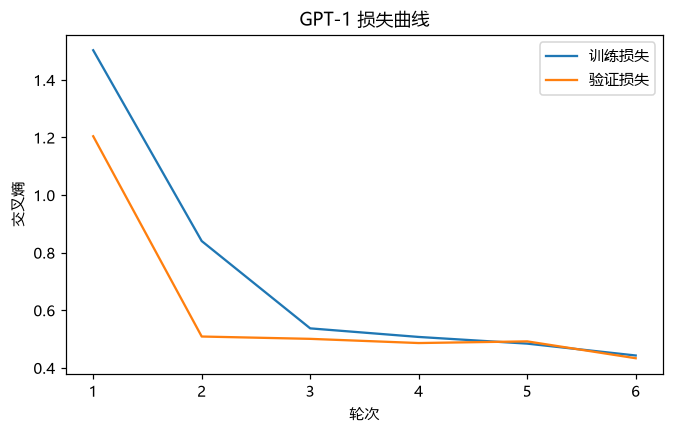

,Accuracy,Precision_macro,Recall_macro,F1_macro,best_epoch
0,0.626603,0.637059,0.592222,0.606656,6


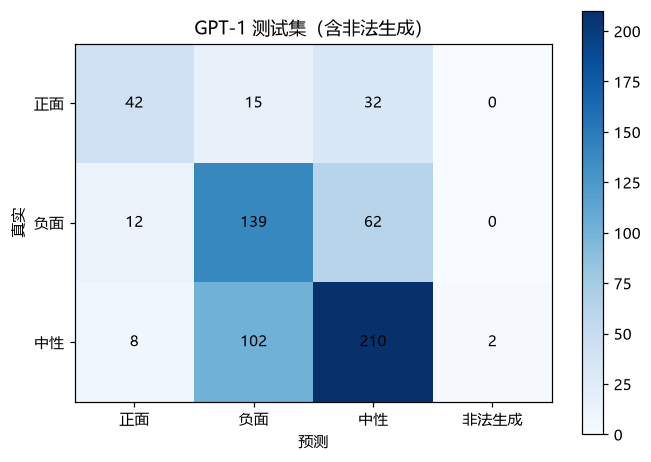

In [8]:
history=pd.DataFrame(records);history.to_csv(RESULT/'training_history.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(history.epoch,history.train_loss,label='训练损失');ax.plot(history.epoch,history.val_loss,label='验证损失');ax.set(xlabel='轮次',ylabel='交叉熵',title=TITLE+' 损失曲线');ax.legend();savefig('training_curves')
result=metrics(df.loc[te,'label'],pred);result['best_epoch']=best_epoch
pd.DataFrame([result]).to_csv(RESULT/'metrics.csv',index=False);display(pd.DataFrame([result]))
out=df.loc[te,['text_clean','emotion','label']].copy();out['prediction']=pred;out.to_csv(RESULT/'test_predictions.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(classification_report(df.loc[te,'label'],pred,labels=[0,1,2],target_names=names,output_dict=True,zero_division=0)).T.to_csv(RESULT/'class_metrics.csv',encoding='utf-8-sig')
# 保留非法生成列，混淆矩阵覆盖全部测试样本。
prediction=pd.read_csv(RESULT/'test_predictions.csv')
cm=confusion_matrix(prediction.label,prediction.prediction,labels=[0,1,2,-1])[:3]
fig,ax=plt.subplots(figsize=(7,5));im=ax.imshow(cm,cmap='Blues');ax.set_xticks(range(4),names+['非法生成']);ax.set_yticks(range(3),names);ax.set(xlabel='预测',ylabel='真实',title=TITLE+' 测试集（含非法生成）')
for i in range(3):
    for j in range(4):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
fig.colorbar(im,ax=ax);savefig('performance')


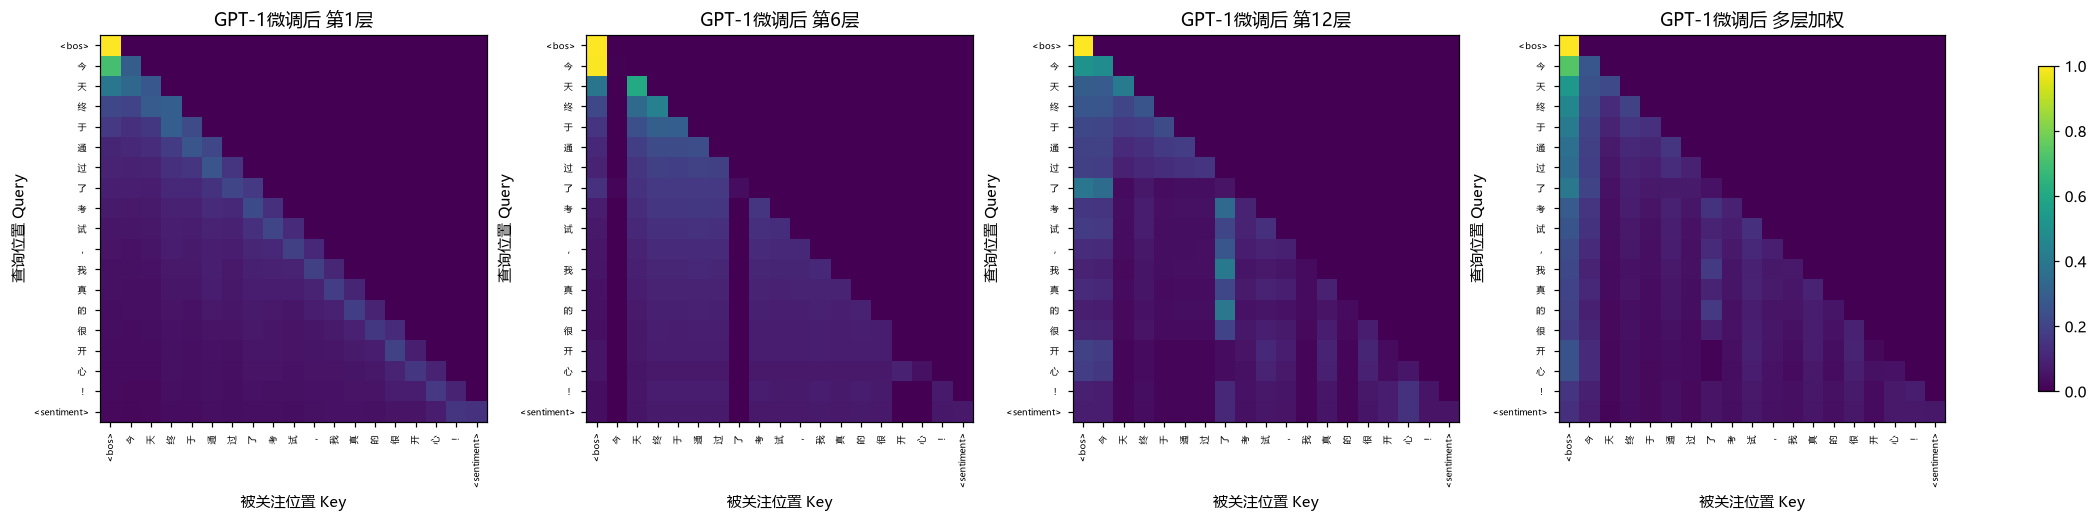

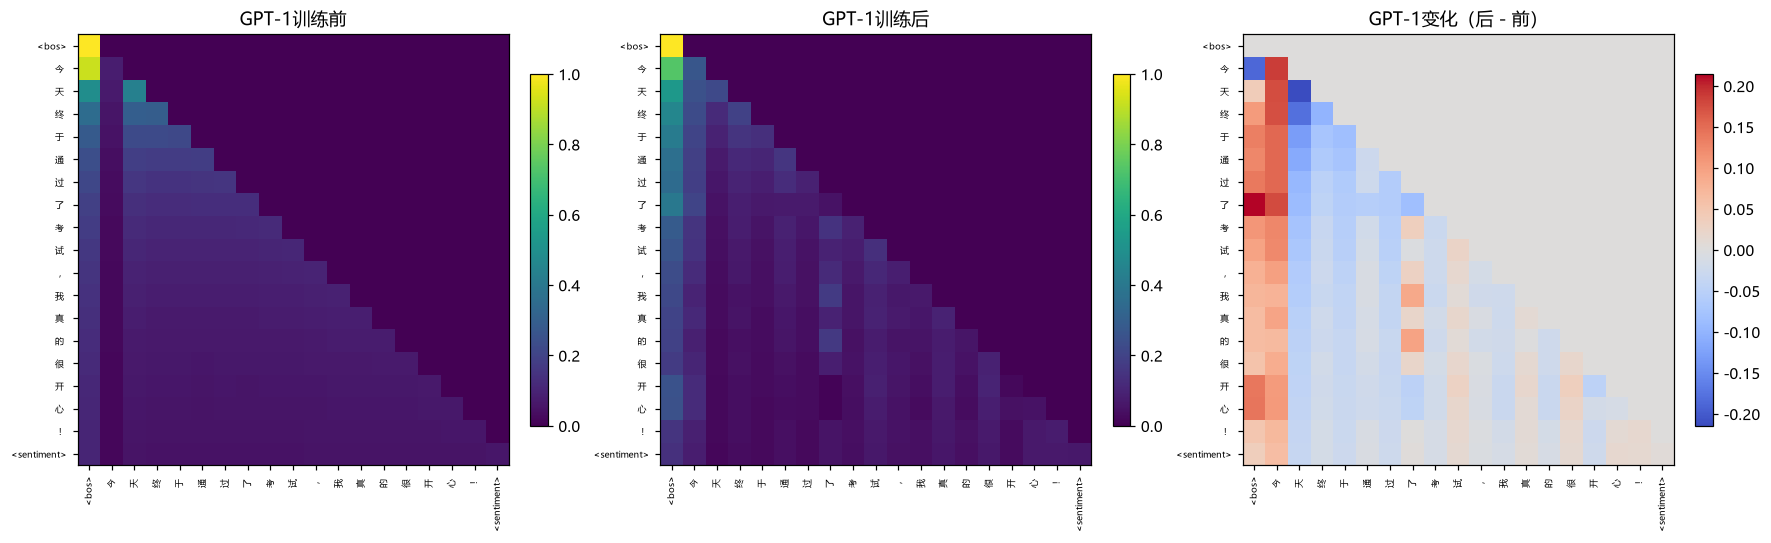

In [9]:
out['generated']=generated;out.to_csv(RESULT/'test_predictions.csv',index=False,encoding='utf-8-sig')
after=attention_arrays(gpt,gi)
attention_plot(after,tokens,'GPT-1微调后','attention_after');compare_attention(before,after,tokens,'GPT-1')
print('非法生成数量',sum(p<0 for p in pred))

,Accuracy,Precision_macro,Recall_macro,F1_macro,best_epoch,model
0,0.899038,0.887256,0.891728,0.888990,5,BERT
1,0.626603,0.637059,0.592222,0.606656,6,GPT-1


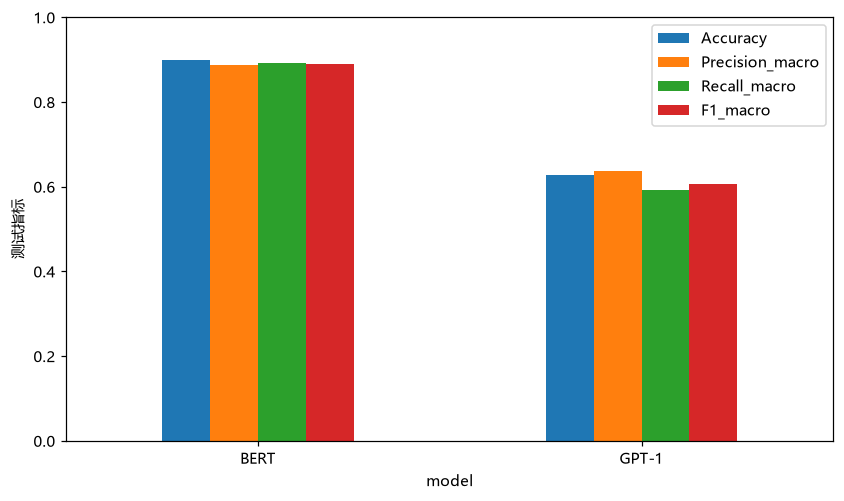

In [10]:
b=pd.read_csv(BASE/'results/exp5B/metrics.csv');b['model']='BERT'
c=pd.read_csv(RESULT/'metrics.csv');c['model']='GPT-1'
comparison=pd.concat([b,c],ignore_index=True);comparison.to_csv(RESULT/'model_comparison.csv',index=False);display(comparison)
comparison.set_index('model')[['Accuracy','Precision_macro','Recall_macro','F1_macro']].plot.bar(rot=0,figsize=(9,5),ylim=(0,1),ylabel='测试指标');savefig('model_comparison')


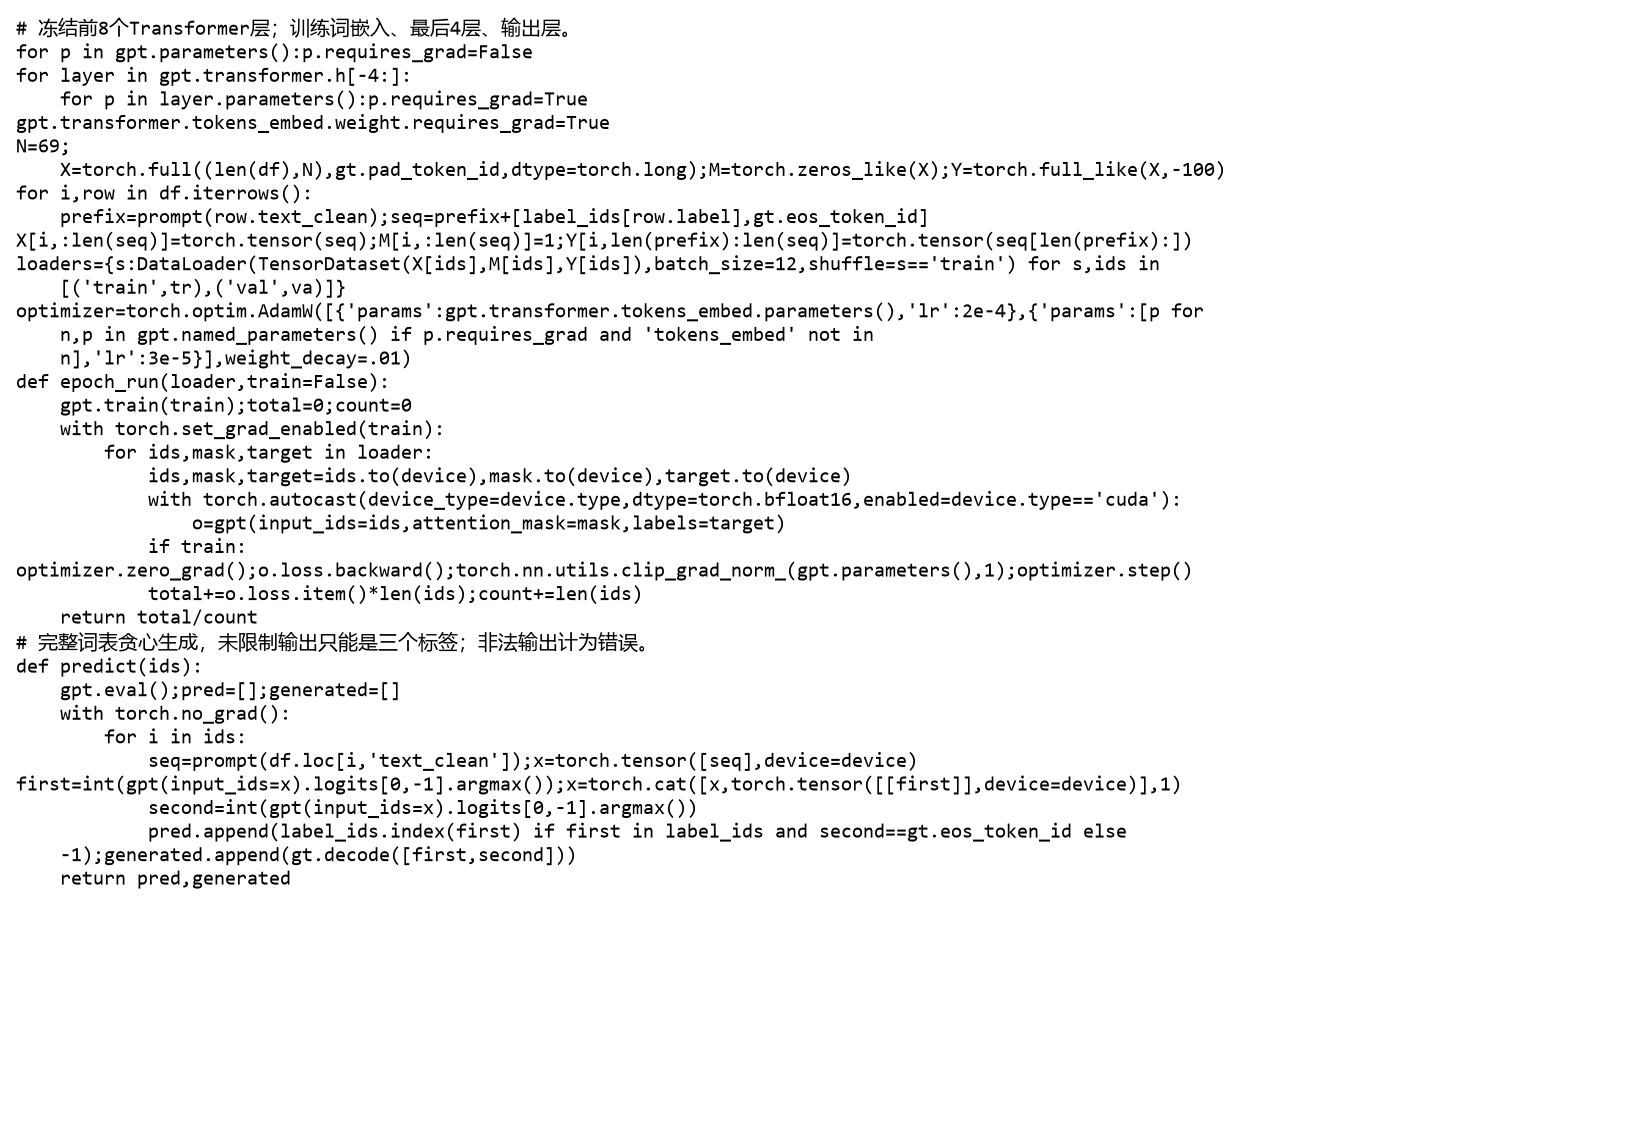

In [11]:
code_image("# 冻结前8个Transformer层；训练词嵌入、最后4层、输出层。\nfor p in gpt.parameters():p.requires_grad=False\nfor layer in gpt.transformer.h[-4:]:\n    for p in layer.parameters():p.requires_grad=True\ngpt.transformer.tokens_embed.weight.requires_grad=True\nN=69; X=torch.full((len(df),N),gt.pad_token_id,dtype=torch.long);M=torch.zeros_like(X);Y=torch.full_like(X,-100)\nfor i,row in df.iterrows():\n    prefix=prompt(row.text_clean);seq=prefix+[label_ids[row.label],gt.eos_token_id]\n    X[i,:len(seq)]=torch.tensor(seq);M[i,:len(seq)]=1;Y[i,len(prefix):len(seq)]=torch.tensor(seq[len(prefix):])\nloaders={s:DataLoader(TensorDataset(X[ids],M[ids],Y[ids]),batch_size=12,shuffle=s=='train') for s,ids in [('train',tr),('val',va)]}\noptimizer=torch.optim.AdamW([{'params':gpt.transformer.tokens_embed.parameters(),'lr':2e-4},{'params':[p for n,p in gpt.named_parameters() if p.requires_grad and 'tokens_embed' not in n],'lr':3e-5}],weight_decay=.01)\ndef epoch_run(loader,train=False):\n    gpt.train(train);total=0;count=0\n    with torch.set_grad_enabled(train):\n        for ids,mask,target in loader:\n            ids,mask,target=ids.to(device),mask.to(device),target.to(device)\n            with torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=device.type=='cuda'):\n                o=gpt(input_ids=ids,attention_mask=mask,labels=target)\n            if train:\n                optimizer.zero_grad();o.loss.backward();torch.nn.utils.clip_grad_norm_(gpt.parameters(),1);optimizer.step()\n            total+=o.loss.item()*len(ids);count+=len(ids)\n    return total/count\n# 完整词表贪心生成，未限制输出只能是三个标签；非法输出计为错误。\ndef predict(ids):\n    gpt.eval();pred=[];generated=[]\n    with torch.no_grad():\n        for i in ids:\n            seq=prompt(df.loc[i,'text_clean']);x=torch.tensor([seq],device=device)\n            first=int(gpt(input_ids=x).logits[0,-1].argmax());x=torch.cat([x,torch.tensor([[first]],device=device)],1)\n            second=int(gpt(input_ids=x).logits[0,-1].argmax())\n            pred.append(label_ids.index(first) if first in label_ids and second==gt.eos_token_id else -1);generated.append(gt.decode([first,second]))\n    return pred,generated\n")